In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

#import models
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

#import metrics
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score,
    ConfusionMatrixDisplay
)

In [ ]:
#1.Загругружаем данные и делаем выборку

df = pd.read_csv('/home/s/DataScince/Sosinovich_DS_2026/Sosinovich_hw_3/heart.csv')

#проверка на пропуски
print("Пропущенные значения до очистки:")
print(df.isna().sum())

#очищаем датасет от пропусков

df = df.dropna()

print(f"\nРазмер датасета после применения dropna: {df.shape}")

X = df.drop(columns=['target'])
y = df['target']

#делаем выборку
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#масштабирование признаков
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)



Пропущенные значения до очистки:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Размер датасета после применения dropna: (303, 14)



Наилучшее число соседей k: 7 (F1-score = 0.9206)

 Метрики для модели: Naive Bayes
Accuracy: 0.8689
Precision: 0.9000
Recall: 0.8438
F1-Score: 0.8710

 Метрики для модели: LogisticRegression
Accuracy: 0.8525
Precision: 0.8710
Recall: 0.8438
F1-Score: 0.8571

 Метрики для модели: kNN (k=7)
Accuracy: 0.9180
Precision: 0.9355
Recall: 0.9062
F1-Score: 0.9206


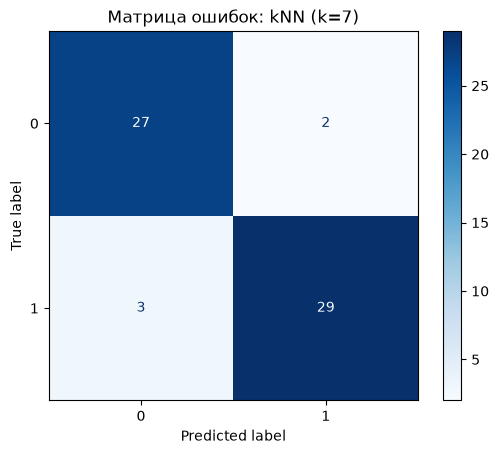

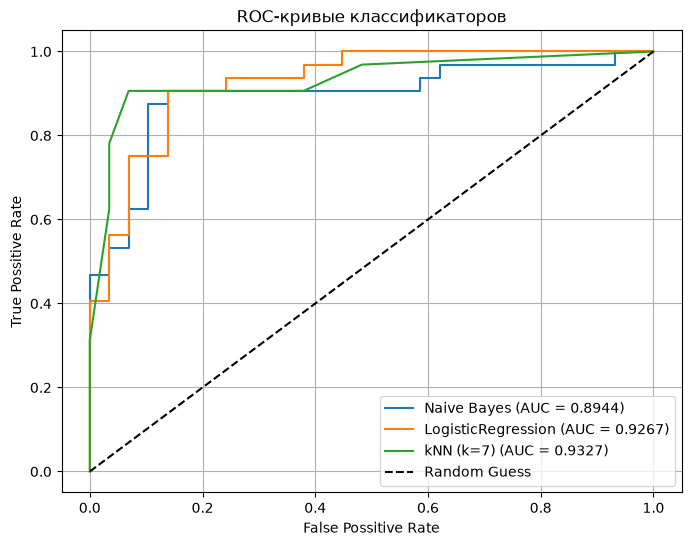

In [4]:
#2.Подбор наилучшего k для kNN
best_k = 1
best_f1 = 0

for k in range(1, 21):
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    knn_temp.fit(X_train_scaled, y_train)
    preds = knn_temp.predict(X_test_scaled)
    current_f1 = f1_score(y_test, preds)

    if current_f1 > best_f1:
        best_f1 = current_f1
        best_k = k
print(f"\nНаилучшее число соседей k: {best_k} (F1-score = {best_f1:.4f})")


#3.Инициализация и обучение моделей
models = {'Naive Bayes': GaussianNB(), 'LogisticRegression': LogisticRegression(max_iter=1000), 
          f'kNN (k={best_k})': KNeighborsClassifier(n_neighbors= best_k)}

predictions = {}
probabilities = {}

for name, model in models.items():
    X_tr = X_train if name == 'Naive Bayes' else X_train_scaled
    X_te = X_test if name == 'Naive Bayes' else X_test_scaled

    model.fit(X_tr, y_train)
    predictions[name] = model.predict(X_te)
    probabilities[name] = np.asarray(model.predict_proba(X_te))[:, 1] #вероятность для ROC-кривой

#4.Оценка моделей и матрицы ошибок
for name in models.keys():
    print(f"\n Метрики для модели: {name}")
    y_pred = predictions[name]

    print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
    print(f"Precision: {precision_score(y_test, y_pred):.4f}")
    print(f"Recall: {recall_score(y_test, y_pred):.4f}")
    print(f"F1-Score: {f1_score(y_test, y_pred):.4f}")

#Визуализация матрицы ошибок
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix = cm)
disp.plot(cmap=plt.cm.Blues)
plt.title(f"Матрица ошибок: {name}")
plt.show()

#5.ROC-анализ(пробно)
plt.figure(figsize=(8, 6))

for name in models.keys():
    fpr, tpr, _ =roc_curve(y_test, probabilities[name])
    auc_value = roc_auc_score(y_test, probabilities[name])
    plt.plot(fpr,tpr, label=f"{name} (AUC = {auc_value:.4f})")
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Possitive Rate')
plt.ylabel('True Possitive Rate')
plt.title('ROC-кривые классификаторов')
plt.legend()
plt.grid(True)
plt.show()